# Моделирование: Bank Marketing — Левин
Предсказываем, согласится ли клиент на депозит (`y`). Опираемся на выводы EDA ([eda_levin.ipynb](eda_levin.ipynb)):
- `duration` — утечка, в основной модели не используем;
- конверсия дрейфует по времени (≈5% → 17% → 52% по годам), поэтому считаем **три** схемы валидации;
- пропуски — осмысленные категории, а не «дыры».

**План:** 1) валидация и метрики → 2) фичи → 3) модели → 4) гипотезы по фичам → 5) сравнение моделей → 6) тюнинг → 7) ансамбль → 8) итог.

## 0. Импорты и данные

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, TimeSeriesSplit, GroupKFold, ParameterSampler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

sns.set_theme(style='whitegrid'); pd.set_option('display.width', 140, 'display.max_columns', 40)
SEED, N_JOBS = 42, 8
N_ITER = 30   # число конфигураций в random search

In [2]:
bm = fetch_ucirepo(id=222)
raw = pd.concat([bm.data.features, bm.data.targets], axis=1)
y = (raw.y == 'yes').astype(int).values
print(raw.shape, f'| доля yes: {y.mean():.3f}')

MONTHS = {m: i + 1 for i, m in enumerate('jan feb mar apr may jun jul aug sep oct nov dec'.split())}
YEAR = 2008 + (raw.month.map(MONTHS).diff().fillna(0) < 0).cumsum().values   # год из порядка строк (EDA 2.2)
PERIOD = YEAR * 100 + raw.month.map(MONTHS).values                            # группа «год-месяц»

(45211, 17) | доля yes: 0.117


## 1. Валидация и метрики
Классы несбалансированы (≈12% «да»), поэтому accuracy не используем. Метрики:
- **ROC-AUC** — качество ранжирования клиентов;
- **PR-AUC** (average precision) — то же, но с упором на редкий класс; базовый уровень = доля «да» (≈0.12);
- **Lift@10%** — во сколько раз доля «да» среди 10% самых «вероятных» клиентов выше средней. Бизнес-смысл: «если обзванивать только топ-10% по модели».

Три схемы (все 5 фолдов):
- **strat** — стандартная Stratified K-fold с перемешиванием. Соседние по времени клиенты попадают и в train, и в test, поэтому оценка **оптимистична**;
- **block** — GroupKFold по периодам «год-месяц»: тест — месяцы, которых нет в train (но обучаемся и на прошлом, и на будущем). Проверяет устойчивость к смене периода;
- **time** — forward-chaining (`TimeSeriesSplit`): учимся на прошлом, тестируем на будущем. Самая строгая, но в ранних фолдах мало данных для обучения.

In [3]:
class BlockCV:   # GroupKFold по периодам; обёртка, чтобы split(X, y) не требовал groups
    def __init__(self, groups, n=5): self.groups, self.n = groups, n
    def split(self, X, y=None): return GroupKFold(self.n).split(X, y, self.groups)

skf, tss = StratifiedKFold(5, shuffle=True, random_state=SEED), TimeSeriesSplit(n_splits=5)
SCHEMES = {'strat': skf, 'block': BlockCV(PERIOD), 'time': tss}

def lift_at(y_true, p, frac=0.10):
    k = int(len(y_true) * frac)
    return y_true[np.argsort(-p)[:k]].mean() / y_true.mean()

def score_oof(y_true, oof, fold):
    # метрики по каждому фолду (только по тестовым строкам), затем среднее
    rows = []
    for f in sorted(set(fold[fold >= 0])):
        m = fold == f
        rows.append((roc_auc_score(y_true[m], oof[m]), average_precision_score(y_true[m], oof[m]), lift_at(y_true[m], oof[m])))
    return pd.DataFrame(rows, columns=['auc', 'pr', 'lift10'])

def evaluate(make, X, cv):
    # make(X) -> новая модель; возвращает метрики по фолдам и out-of-fold предсказания
    oof, fold = np.full(len(y), np.nan), np.full(len(y), -1)
    for i, (tr, te) in enumerate(cv.split(X, y)):
        m = make(X).fit(X.iloc[tr], y[tr])
        oof[te], fold[te] = m.predict_proba(X.iloc[te])[:, 1], i
    return score_oof(y, oof, fold), oof, fold

def both(make, X):
    # прогон по всем схемам, сводка в одну строку
    res = {k: evaluate(make, X, cv) for k, cv in SCHEMES.items()}
    row = {f'{k}_{m}': res[k][0][m].mean() for k in SCHEMES for m in ('auc', 'pr', 'lift10')}
    return row, res

## 2. Фичи
Все фичи считаются **построчно** (без таргета и без статистик по всей выборке) — значит, утечки через фичи нет.
Пропуски заполняем осмысленно (EDA, H1/H2): `poutcome=NaN` → `no_prev`, остальные → `unknown`.
Год **не используем** — в реальном применении «будущего года» нет (но проверим его как гипотезу в разделе 4).

| Фича | Идея (из EDA) |
|---|---|
| `prev_contacted`, `pdays_clean` | `pdays=-1` — маркер «не звонили»; отделяем флаг от числа дней |
| `prev_success` | `poutcome=success` → конверсия ≈65% |
| `contact_unknown` | пропуск `contact` (но он в основном прокси периода мая–июня 2008) |
| `month_num` | порядковый месяц |
| `age_bin` | U-образная зависимость от возраста |
| `balance_log`, `balance_neg` | скошенность, плато, отрицательные балансы |
| `n_loans` | сколько долговых флагов (`housing`, `loan`, `default`) |
| `campaign_clip`, `previous_clip` | обрезаем хвосты |
| `job_sr` | `student`/`retired` — самые конвертируемые |

In [4]:
CATS = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

def build(fe=True, duration=False, year=False, drop=()):
    d = raw.drop(columns='y').rename(columns={'day_of_week': 'day'}).copy()
    for c in CATS: d[c] = d[c].fillna('no_prev' if c == 'poutcome' else 'unknown')
    if fe:
        d['month_num'] = d.month.map(MONTHS)
        d['prev_contacted'] = (d.pdays != -1).astype(int)
        d['pdays_clean'] = d.pdays.where(d.pdays > 0)
        d['prev_success'] = (d.poutcome == 'success').astype(int)
        d['contact_unknown'] = (d.contact == 'unknown').astype(int)
        d['age_bin'] = pd.cut(d.age, [0, 25, 30, 40, 50, 60, 120], labels=['<=25', '26-30', '31-40', '41-50', '51-60', '60+']).astype(str)
        d['balance_log'] = np.sign(d.balance) * np.log1p(d.balance.abs())
        d['balance_neg'] = (d.balance < 0).astype(int)
        d['n_loans'] = (d.housing == 'yes').astype(int) + (d.loan == 'yes') + (d.default == 'yes')
        d['campaign_clip'] = d.campaign.clip(upper=10)
        d['previous_clip'] = d.previous.clip(upper=10)
        d['job_sr'] = d.job.isin(['student', 'retired']).astype(int)
        d = d.drop(columns='pdays')
    if year: d['year'] = YEAR
    if not duration: d = d.drop(columns='duration')
    d = d.drop(columns=list(drop))
    for c in [*CATS, 'age_bin']:
        if c in d: d[c] = d[c].astype('category')
    return d.reset_index(drop=True)

X_raw, X_fe = build(fe=False), build(fe=True)
print(X_raw.shape, X_fe.shape); X_fe.head(3)

(45211, 15) (45211, 26)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,previous,poutcome,month_num,prev_contacted,pdays_clean,prev_success,contact_unknown,age_bin,balance_log,balance_neg,n_loans,campaign_clip,previous_clip,job_sr
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,51-60,7.670429,0,1,1,0,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,41-50,3.401197,0,1,1,0,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,1,0,no_prev,5,0,NaN,0,1,31-40,1.098612,0,2,1,0,0


## 3. Модели
Линейная модель и лес получают one-hot, бустинги — категории нативно. Гиперпараметры пока «разумные по умолчанию»; тюнинг — в разделе 6.

In [5]:
def cats_nums(X):
    cats = [c for c in X if str(X[c].dtype) == 'category']; return cats, [c for c in X if c not in cats]

def prep_lin(X):
    cats, nums = cats_nums(X)
    return ColumnTransformer([('n', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), nums),
                              ('c', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cats)])

def make_lr(X, C=0.3):   return make_pipeline(prep_lin(X), LogisticRegression(C=C, max_iter=3000))
def make_rf(X):          return make_pipeline(prep_lin(X), RandomForestClassifier(300, min_samples_leaf=20, n_jobs=N_JOBS, random_state=SEED))

LGB_P = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
def make_lgb(X, **kw):   return LGBMClassifier(**{**LGB_P, **kw}, n_jobs=N_JOBS, random_state=SEED, verbose=-1)
def make_xgb(X):         return XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                              enable_categorical=True, tree_method='hist', n_jobs=N_JOBS, random_state=SEED)
def make_cat(X):
    cats, _ = cats_nums(X)
    to_str = FunctionTransformer(lambda d: d.astype({c: str for c in cats}))   # CatBoost хочет строки
    return make_pipeline(to_str, CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, cat_features=cats,
                                                     thread_count=N_JOBS, random_seed=SEED, verbose=0))

## 4. Гипотезы по фичам (ablation)
Меняем **одну вещь** относительно базы (LightGBM + фичи из раздела 2) и смотрим на три схемы. Разница < ~0.005 AUC — в пределах шума.

Главный вопрос, который поставил EDA: признаки `month`, `day`, `contact_unknown` (и категория `contact=unknown`) — это **прокси периода** (май–июнь 2008 и т.п.). Помогают ли они предсказывать *новый* период или только «запоминают» старый?

In [6]:
PROXY = ['month', 'month_num', 'day', 'contact_unknown']
base = both(make_lgb, X_fe)[0]
exps = {
 'H1. сырые признаки вместо fe':                          (make_lgb, X_raw),
 'H2. + duration (утечка, потолок)':                      (make_lgb, build(duration=True)),
 'H3. + год (прокси дрейфа)':                             (make_lgb, build(year=True)),
 'H4a. без прокси времени (month, day, contact_unknown)': (make_lgb, build(drop=PROXY)),
 'H4b. + без contact (в нём «unknown» = май–июнь 2008)':  (make_lgb, build(drop=PROXY + ['contact'])),
 'H5. без слабых (default, marital, education, loan)':    (make_lgb, build(drop=['default', 'marital', 'education', 'loan'])),
 'H6. без дублей (age_bin, balance_log, *_clip)':         (make_lgb, build(drop=['age_bin', 'balance_log', 'campaign_clip', 'previous_clip'])),
 'H7. веса классов (is_unbalance)':                       (lambda X: make_lgb(X, is_unbalance=True), X_fe),
 'H8. мелкие деревья (num_leaves=7, 500 шт.)':            (lambda X: make_lgb(X, num_leaves=7, n_estimators=500), X_fe),
}
out = [{'эксперимент': 'БАЗА: LightGBM + fe', **base}]
for k, (mk, X) in exps.items(): out.append({'эксперимент': k, **both(mk, X)[0]})
hyp = pd.DataFrame(out).set_index('эксперимент')
auc = hyp[['strat_auc', 'block_auc', 'time_auc']]
pd.concat([auc.round(3), auc.sub(auc.iloc[0]).add_prefix('Δ ').round(3), hyp[['strat_lift10', 'block_lift10', 'time_lift10']].round(2)], axis=1)

,strat_auc,block_auc,time_auc,Δ strat_auc,Δ block_auc,Δ time_auc,strat_lift10,block_lift10,time_lift10
эксперимент,,,,,,,,,
БАЗА: LightGBM + fe,0.803,0.655,0.574,0.000,0.000,0.000,4.45,2.97,1.35
H1. сырые признаки вместо fe,0.803,0.653,0.563,0.000,-0.003,-0.012,4.43,2.96,1.28
"H2. + duration (утечка, потолок)",0.939,0.823,0.872,0.136,0.168,0.298,5.45,3.91,5.40
H3. + год (прокси дрейфа),0.811,0.730,0.575,0.008,0.074,0.000,4.57,3.66,1.37
"H4a. без прокси времени (month, day, contact_unknown)",0.758,0.723,0.569,-0.045,0.068,-0.006,3.79,3.71,1.41
H4b. + без contact (в нём «unknown» = май–июнь 2008),0.737,0.719,0.574,-0.065,0.063,-0.000,3.72,3.61,1.48
"H5. без слабых (default, marital, education, loan)",0.798,0.646,0.565,-0.004,-0.009,-0.009,4.42,2.98,1.29
"H6. без дублей (age_bin, balance_log, *_clip)",0.803,0.662,0.579,0.000,0.007,0.005,4.43,3.08,1.41
H7. веса классов (is_unbalance),0.801,0.660,0.565,-0.002,0.004,-0.009,4.39,3.19,1.27


**Как читать:** `Δ` — разница AUC с базой; справа Lift@10%.
- **H2** — «цена» утечки `duration`: огромный скачок на всех схемах (его нельзя использовать).
- **H3/H4** — признаки периода по-разному ведут себя в схемах: случайная CV (`strat`) их «любит» (они позволяют запомнить период), а схемы со сдвигом периода (`block`, `time`) — нет.

In [7]:
# Выбираем набор фичей по схемам со сдвигом периода (block и time); strat — только справка
shift = lambda r: (r.block_auc + r.time_auc) / 2
cand = {'fe (все фичи)': ([], shift(hyp.iloc[0])), 'без прокси': (PROXY, shift(hyp.loc['H4a. без прокси времени (month, day, contact_unknown)'])),
        'без прокси и contact': (PROXY + ['contact'], shift(hyp.loc['H4b. + без contact (в нём «unknown» = май–июнь 2008)']))}
NP_NAME = max(cand, key=lambda k: cand[k][1]); NP_DROP = cand[NP_NAME][0]
print({k: round(v[1], 4) for k, v in cand.items()}); print('Выбран набор:', NP_NAME)
X_np = build(drop=NP_DROP); print(X_np.shape)

{'fe (все фичи)': np.float64(0.615), 'без прокси': np.float64(0.6461), 'без прокси и contact': np.float64(0.6466)}
Выбран набор: без прокси и contact
(45211, 21)


## 5. Сравнение моделей
Все модели на двух наборах: `fe` (все фичи) и `np` (выбранный устойчивый набор без прокси периода).

In [8]:
runs = {}
def run(name, make, X):
    row, res = both(make, X); runs[name] = res; return {'model': name, **row}

makers = {'LogReg': make_lr, 'RandomForest': make_rf, 'LightGBM': make_lgb, 'XGBoost': make_xgb, 'CatBoost': make_cat}
rows = [run(f'{n} ({tag})', mk, X) for tag, X in [('fe', X_fe), ('np', X_np)] for n, mk in makers.items()]
cmp = pd.DataFrame(rows).set_index('model'); cmp.round(3)

,strat_auc,strat_pr,strat_lift10,block_auc,block_pr,block_lift10,time_auc,time_pr,time_lift10
model,,,,,,,,,
LogReg (fe),0.773,0.412,4.166,0.669,0.327,3.342,0.598,0.192,1.552
RandomForest (fe),0.797,0.437,4.240,0.676,0.338,3.432,0.588,0.183,1.458
LightGBM (fe),0.803,0.459,4.450,0.655,0.294,2.968,0.574,0.183,1.353
XGBoost (fe),0.803,0.459,4.418,0.653,0.295,2.938,0.578,0.181,1.276
CatBoost (fe),0.803,0.455,4.386,0.654,0.306,3.075,0.579,0.187,1.429
LogReg (np),0.736,0.372,3.659,0.722,0.366,3.627,0.607,0.207,1.689
RandomForest (np),0.741,0.381,3.780,0.722,0.374,3.789,0.599,0.190,1.578
LightGBM (np),0.737,0.383,3.724,0.719,0.366,3.609,0.574,0.186,1.477
XGBoost (np),0.739,0.383,3.729,0.722,0.372,3.666,0.576,0.186,1.484


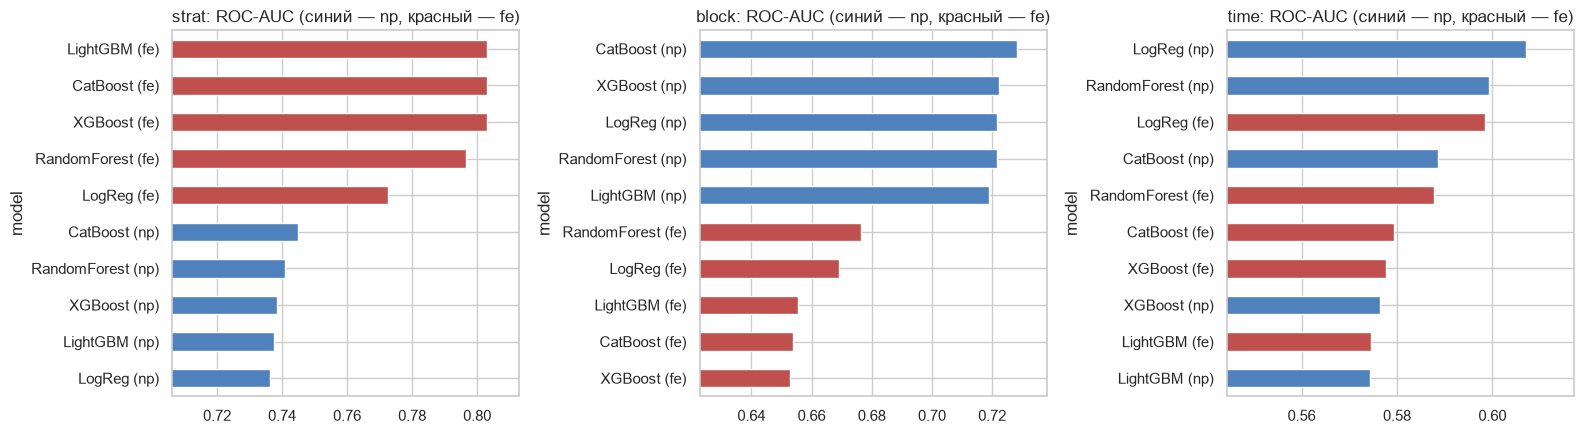

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, k in zip(axs, ['strat', 'block', 'time']):
    cmp[f'{k}_auc'].sort_values().plot.barh(ax=ax, color=['#c0504d' if 'fe)' in i else '#4f81bd' for i in cmp[f'{k}_auc'].sort_values().index])
    ax.set_title(f'{k}: ROC-AUC (синий — np, красный — fe)'); ax.set_xlim(cmp[f'{k}_auc'].min() - .03, cmp[f'{k}_auc'].max() + .01)
plt.tight_layout(); plt.show()

## 6. Тюнинг LightGBM
Random search на наборе `np`; конфигурацию оцениваем по **среднему AUC схем block и time** (устойчивость к сдвигу периода).

In [10]:
space = dict(n_estimators=[150, 250, 400, 600], learning_rate=[0.02, 0.03, 0.05, 0.08], num_leaves=[3, 4, 7, 15, 31],
             min_child_samples=[20, 50, 100, 200, 400], subsample=[0.6, 0.8, 1.0], colsample_bytree=[0.5, 0.7, 0.9],
             reg_lambda=[0, 1, 5, 20, 50], max_cat_to_onehot=[4, 8, 16], cat_smooth=[10, 30, 100])
cands, tune = list(ParameterSampler(space, N_ITER, random_state=SEED)), []
for p in cands:
    r, _ = both(lambda X: make_lgb(X, **p), X_np)
    tune.append({**r, 'score': (r['block_auc'] + r['time_auc']) / 2})
tune = pd.DataFrame(tune).sort_values('score', ascending=False)
pd.concat([pd.DataFrame(cands).loc[tune.index], tune], axis=1).head(5).round(4)

,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,max_cat_to_onehot,learning_rate,colsample_bytree,cat_smooth,strat_auc,strat_pr,strat_lift10,block_auc,block_pr,block_lift10,time_auc,time_pr,time_lift10,score
5,0.6,1,4,400,100,8,0.02,0.5,100,0.7439,0.3833,3.8108,0.7246,0.3738,3.7894,0.6050,0.1971,1.5892,0.6648
24,0.8,50,4,400,50,16,0.05,0.7,30,0.7449,0.3882,3.7862,0.7271,0.3788,3.7886,0.6017,0.1951,1.5371,0.6644
14,1.0,1,4,150,50,8,0.05,0.5,30,0.7434,0.3828,3.8108,0.7233,0.3713,3.7739,0.6047,0.2006,1.6368,0.6640
0,1.0,5,3,400,50,4,0.08,0.5,100,0.7442,0.3884,3.8108,0.7252,0.3774,3.7500,0.6027,0.1985,1.6183,0.6640
7,0.6,50,3,600,100,8,0.05,0.7,100,0.7442,0.3865,3.7937,0.7265,0.3765,3.7519,0.6012,0.1953,1.6308,0.6638


In [11]:
best = cands[tune.index[0]]; d0 = cmp.loc['LightGBM (np)']
print('Лучшие параметры:', best)
print(f"Тюнинг: score {tune.score.iloc[0]:.4f} vs дефолт {(d0.block_auc + d0.time_auc) / 2:.4f}")

Лучшие параметры: {'subsample': 0.6, 'reg_lambda': 1, 'num_leaves': 4, 'n_estimators': 400, 'min_child_samples': 100, 'max_cat_to_onehot': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.5, 'cat_smooth': 100}
Тюнинг: score 0.6648 vs дефолт 0.6466


## 7. Ансамбль
Усредняем вероятности нескольких разных моделей на наборе `np` (out-of-fold, поэтому честно): тюнёный LightGBM, CatBoost, RandomForest, LogReg.

In [12]:
runs['LGBM tuned (np)'] = both(lambda X: make_lgb(X, **best), X_np)[1]
def blend(names, scheme):
    oof = np.mean([runs[n][scheme][1] for n in names], axis=0)
    return score_oof(y, oof, runs[names[0]][scheme][2]).mean(), oof

sets = {'LGBM tuned': ['LGBM tuned (np)'],
        'LGBM + CatBoost': ['LGBM tuned (np)', 'CatBoost (np)'],
        'LGBM + CatBoost + RF': ['LGBM tuned (np)', 'CatBoost (np)', 'RandomForest (np)'],
        'LGBM + CatBoost + RF + LogReg': ['LGBM tuned (np)', 'CatBoost (np)', 'RandomForest (np)', 'LogReg (np)']}
ens = pd.DataFrame({k: pd.concat({s: blend(v, s)[0] for s in SCHEMES}) for k, v in sets.items()}).T
ens.round(3)

strat                block                 time              
                                 auc     pr lift10    auc     pr lift10    auc     pr lift10
LGBM tuned                     0.744  0.383  3.811  0.725  0.374  3.789  0.605  0.197  1.589
LGBM + CatBoost                0.746  0.387  3.811  0.727  0.381  3.816  0.600  0.192  1.472
LGBM + CatBoost + RF           0.746  0.387  3.813  0.727  0.381  3.818  0.603  0.193  1.546
LGBM + CatBoost + RF + LogReg  0.745  0.385  3.799  0.727  0.378  3.801  0.606  0.200  1.612

## 8. Итоговая модель: детальная оценка
Лучший вариант из раздела 7 — по среднему AUC схем block и time. Смотрим разброс по фолдам, sanity-check на утечки, lift по децилям и важность признаков.

In [13]:
final_name = max(sets, key=lambda k: np.mean([ens.loc[k, (s, 'auc')] for s in ('block', 'time')]))
final_models = sets[final_name]; print('Финальная модель:', final_name)
oofs = {s: blend(final_models, s)[1] for s in SCHEMES}; folds = {s: runs[final_models[0]][s][2] for s in SCHEMES}
for s in SCHEMES:
    t = score_oof(y, oofs[s], folds[s]); ids = sorted(set(folds[s][folds[s] >= 0]))
    t['тест, n'] = [(folds[s] == i).sum() for i in ids]; t['доля yes в тесте'] = [y[folds[s] == i].mean() for i in ids]
    print(f'\nСхема {s}: метрики по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)'); display(t.round(3))

Финальная модель: LGBM + CatBoost + RF + LogReg

Схема strat: метрики по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.735,0.373,3.574,9043,0.117
1,0.755,0.395,4.003,9042,0.117
2,0.741,0.383,3.791,9042,0.117
3,0.729,0.365,3.602,9042,0.117
4,0.765,0.408,4.027,9042,0.117



Схема block: метрики по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.820,0.506,5.606,9054,0.091
1,0.712,0.324,3.557,9059,0.112
2,0.641,0.278,2.461,8998,0.142
3,0.746,0.407,3.519,9073,0.140
4,0.716,0.377,3.863,9027,0.100



Схема time: метрики по фолдам (PR-AUC между фолдами сравнивать нельзя — разная доля yes)


,auc,pr,lift10,"тест, n",доля yes в тесте
0,0.568,0.066,1.543,7535,0.052
1,0.553,0.072,1.304,7535,0.062
2,0.550,0.067,1.157,7535,0.059
3,0.685,0.272,2.485,7535,0.136
4,0.676,0.522,1.568,7535,0.363


In [14]:
# Sanity-check: на перемешанном таргете AUC должен быть ≈ 0.5 (иначе где-то утечка)
y_perm = np.random.default_rng(SEED).permutation(y)
a = [roc_auc_score(y_perm[te], make_lgb(X_np, **best).fit(X_np.iloc[tr], y_perm[tr]).predict_proba(X_np.iloc[te])[:, 1]) for tr, te in skf.split(X_np, y)]
print(f'Перемешанный таргет: AUC = {np.mean(a):.3f}  (ожидаем ≈ 0.5)')

# Повторная стратифицированная CV (5x3) для устойчивой оценки одиночного LightGBM
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
aucs = [roc_auc_score(y[te], make_lgb(X_np, **best).fit(X_np.iloc[tr], y[tr]).predict_proba(X_np.iloc[te])[:, 1]) for tr, te in rskf.split(X_np, y)]
print(f'LightGBM tuned (np), strat 5x3: AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}')

Перемешанный таргет: AUC = 0.505  (ожидаем ≈ 0.5)


LightGBM tuned (np), strat 5x3: AUC = 0.7441 ± 0.0092


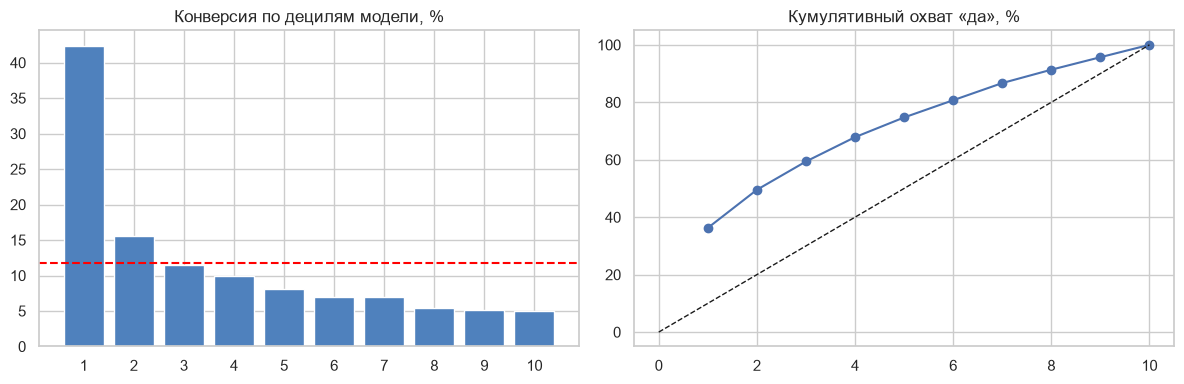

,mean,sum,lift,накоп. доля всех yes
дециль,,,,
1,0.424,1918,3.626,0.363
2,0.155,702,1.327,0.495
3,0.115,521,0.985,0.594
4,0.099,448,0.847,0.679
5,0.080,363,0.686,0.747
6,0.070,317,0.599,0.807
7,0.070,316,0.597,0.867
8,0.054,246,0.465,0.913
9,0.051,230,0.435,0.957


In [15]:
# Lift по децилям (OOF блочной CV — честная оценка): куда звонить в первую очередь
d = pd.DataFrame({'p': oofs['block'], 'y': y}); d['дециль'] = pd.qcut(d.p.rank(method='first', ascending=False), 10, labels=range(1, 11))
g = d.groupby('дециль', observed=True).y.agg(['mean', 'sum']); g['lift'] = g['mean'] / y.mean(); g['накоп. доля всех yes'] = g['sum'].cumsum() / y.sum()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(g.index.astype(str), g['mean'] * 100, color='#4f81bd'); axs[0].axhline(y.mean() * 100, color='red', ls='--'); axs[0].set_title('Конверсия по децилям модели, %')
axs[1].plot(range(1, 11), g['накоп. доля всех yes'] * 100, 'o-'); axs[1].plot([0, 10], [0, 100], 'k--', lw=1); axs[1].set_title('Кумулятивный охват «да», %')
plt.tight_layout(); plt.show(); g.round(3)

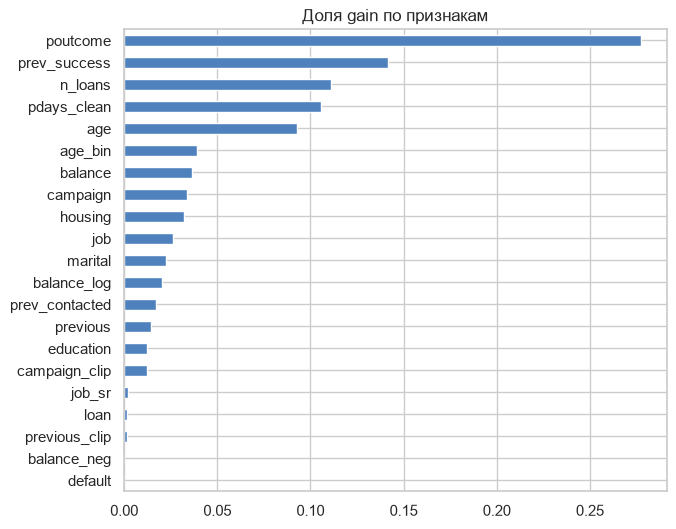

In [16]:
# Важность признаков (gain) финального LightGBM на всех данных
m = make_lgb(X_np, **best).fit(X_np, y)
imp = pd.Series(m.booster_.feature_importance('gain'), index=X_np.columns).sort_values()
(imp / imp.sum()).plot.barh(figsize=(7, 6), color='#4f81bd'); plt.title('Доля gain по признакам'); plt.show()

In [17]:
# Итог: финальная модель по трём схемам; для сравнения — «случайный» классификатор (AUC 0.5, PR = доля yes, lift 1)
summary = pd.DataFrame({s: blend(final_models, s)[0] for s in SCHEMES}).T
summary['baseline PR'] = [y.mean()] * 3; summary.round(3)

,auc,pr,lift10,baseline PR
strat,0.745,0.385,3.799,0.117
block,0.727,0.378,3.801,0.117
time,0.606,0.200,1.612,0.117


## 9. Вердикт

**Финальная модель:** ансамбль (среднее вероятностей) тюнёного LightGBM + CatBoost + RandomForest + LogReg на фичах без признаков-прокси периода (`month`, `day`, `contact`, `contact_unknown`), без `duration`.

| Схема валидации | ROC-AUC | PR-AUC (база 0.117) | Lift@10% |
|---|---|---|---|
| strat (случайные 5 фолдов) — оптимистично | **0.745** | 0.385 | 3.8 |
| block (тест на новых месяцах) — основная | **0.727** | 0.378 | 3.8 |
| time (прошлое → будущее) — строгая | **0.606** | 0.200 | 1.6 |

**Что это значит на практике.** Если обзванивать только 10% клиентов с наибольшей вероятностью, конверсия среди них ≈ **42%** против 11.7% в среднем; топ-10% охватывает ≈ 36% всех «да», топ-20% — ≈ 50% (OOF блочной CV). Ожидаемое качество на новом периоде: AUC ≈ 0.6–0.73 в зависимости от того, насколько изменится политика обзвона.

**Главные выводы**
1. **Случайная CV завышает качество.** На ней LightGBM с «месяц/день/contact» даёт AUC 0.80, но на новых месяцах — всего 0.655. Эти признаки позволяют запомнить период (EDA: май–июнь 2008, день месяца), а не клиента.
2. **Без прокси периода качество на новых периодах выросло:** block 0.655 → 0.72 (H4), при этом на случайной CV оно «падает» 0.80 → 0.74 — это не потеря, а исчезновение эффекта запоминания.
3. **`duration` — утечка:** с ним AUC 0.94 / 0.82 / 0.87 (strat / block / time). В модель не берём.
4. **Год помогает в блочной CV (+0.07), но недоступен в будущем** — не используем.
5. **Фичи и ансамбль дают мало.** Feature engineering ≈ 0 (H1, H6 в пределах шума); ансамбль лучше одиночного LightGBM лишь на ~0.002 AUC (block 0.727 vs 0.725); простая LogReg на `np` даёт block 0.722. Выбор модели важен меньше, чем выбор признаков и схемы валидации. Тюнинг дал +0.018 по среднему block/time — в основном за счёт очень мелких деревьев (`num_leaves` 3–4) и регуляризации.
6. **Веса классов** не помогли (H7): для ранжирования они не нужны, порог подбирается отдельно.
7. **Самые важные признаки** (gain): `poutcome` 28%, `prev_success` 14%, `n_loans` 11%, `pdays_clean` 11%, `age` 9% (+ `age_bin`), затем `balance`, `campaign`. То есть работает история прошлых кампаний, долговая нагрузка и возраст — как и в EDA.

**Ограничения и честные оговорки**
- В строгой схеме **time** первые три фолда (только 2008 год, мало данных для обучения) дают AUC ≈ 0.55; поздние — 0.68. Это не «модель сломана», а реальная неустойчивость к смене политики обзвона. Значения PR/Lift между фолдами с разной долей «да» напрямую сравнивать нельзя.
- Отложенной тестовой выборки нет: все оценки — кросс-валидация; тюнинг шёл по той же CV (30 конфигураций, топ-5 различаются на ≈0.001, поэтому оптимизм малый).
- Выбор набора фичей `np` (с/без `contact`) — на грани шума (0.6461 vs 0.6466); оставили без `contact` как более принципиальный (его `unknown` = май–июнь 2008).
- Sanity-check: AUC на перемешанном таргете 0.505 — утечек через фичи нет. Повторная CV 5×3: 0.744 ± 0.009.

**Что дальше:** подбор порога под бизнес-метрику (стоимость звонка vs доход от депозита); калибровка вероятностей; проверка устойчивости на более поздних данных (если появятся); возможно, отдельные модели для клиентов с историей прошлых кампаний и без неё.
